In [1]:
import os, sys
import warnings
warnings.filterwarnings('ignore')
from IPython.display import display, Markdown, Math
import numpy as np
import pandas as pd
import networkx as nx
from scipy.stats import norm
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)

# Versión local de la librería: se busca src/pmule.py subiendo desde el directorio actual
_aqui = os.path.abspath('.')
while _aqui != os.path.dirname(_aqui) and not os.path.isfile(os.path.join(_aqui, 'src', 'pmule.py')):
    _aqui = os.path.dirname(_aqui)
sys.path.append(os.path.join(_aqui, 'src'))
from pmule import (PredecessorTable, ProjectGraph, EarnedValue,
                   pinta_tikz, plot_cargas, plot_curvas_valor_ganado,
                   tanto_por_uno, ordena_rutas)

GANTT_PARAMS = dict(arrows=True)   # flechas de prelación en los diagramas de Gantt (rojas las críticas)

In [2]:
# Funciones auxiliares para mostrar los cálculos intermedios paso a paso
from itertools import combinations as _combinations


def detalle_tiempos_nodos(proyecto, duraciones):
    """Tiempos tempranos y tardíos de los nodos con los candidatos que se comparan en cada uno."""
    G = proyecto.pert_graph
    d = {data['activity']: (0 if data['activity'].startswith('@') else int(duraciones[data['activity']]))
         for _, _, data in G.edges(data=True)}
    nodos = list(proyecto.nodes)
    early, filas = {}, []
    for j in nodos:
        entrantes = [(i, data['activity']) for i, _, data in G.in_edges(j, data=True)]
        if not entrantes:
            early[j] = 0
            filas.append({'nodo': j, 'candidatos t_i + d_ij': 'nodo inicial', 'tiempo temprano = máx': 0})
            continue
        cand = {f'{a}: {early[i]} + {d[a]} = {early[i] + d[a]}': early[i] + d[a] for i, a in entrantes}
        early[j] = max(cand.values())
        filas.append({'nodo': j, 'candidatos t_i + d_ij': '; '.join(cand), 'tiempo temprano = máx': early[j]})
    tempranos = pd.DataFrame(filas).set_index('nodo')
    late, filas = {}, []
    for i in reversed(nodos):
        salientes = [(j, data['activity']) for _, j, data in G.out_edges(i, data=True)]
        if not salientes:
            late[i] = early[i]
            filas.append({'nodo': i, 'candidatos t*_j − d_ij': 'nodo final (= su tiempo temprano)', 'tiempo tardío = mín': late[i]})
            continue
        cand = {f'{a}: {late[j]} − {d[a]} = {late[j] - d[a]}': late[j] - d[a] for j, a in salientes}
        late[i] = min(cand.values())
        filas.append({'nodo': i, 'candidatos t*_j − d_ij': '; '.join(cand), 'tiempo tardío = mín': late[i]})
    tardios = pd.DataFrame(filas).set_index('nodo')
    return tempranos, tardios


def detalle_holguras(calendario, prelaciones):
    """Cómo se obtiene cada fecha y cada holgura a partir de las vecinas."""
    pred = prelaciones.immediate_predecessor
    suc = {a: sorted(s for s, ps in pred.items() if a in ps) for a in calendario.index}
    fin = int(calendario['fin_mas_temprano'].max())
    filas = []
    for a in calendario.index:
        ES, EF = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'fin_mas_temprano'])
        LS, LF = int(calendario.loc[a, 'inicio_mas_tardio']), int(calendario.loc[a, 'fin_mas_tardio'])
        dur = int(calendario.loc[a, 'duracion'])
        ps, ss = sorted(pred[a]), suc[a]
        ef_pred = {p: int(calendario.loc[p, 'fin_mas_temprano']) for p in ps}
        es_suc = {s: int(calendario.loc[s, 'inicio_mas_temprano']) for s in ss}
        lf_pred = {p: int(calendario.loc[p, 'fin_mas_tardio']) for p in ps}
        ls_suc = {s: int(calendario.loc[s, 'inicio_mas_tardio']) for s in ss}
        min_es_suc = min(es_suc.values()) if es_suc else fin
        max_lf_pred = max(lf_pred.values()) if lf_pred else 0
        filas.append({
            'actividad': a,
            'ES = máx EF pred.': (f"máx({', '.join(f'{p}: {v}' for p, v in ef_pred.items())}) = {ES}" if ps else f'inicial → {ES}'),
            'EF = ES + d': f'{ES} + {dur} = {EF}',
            'LF = mín LS suc.': (f"mín({', '.join(f'{s}: {v}' for s, v in ls_suc.items())}) = {LF}" if ss else f'final → {LF}'),
            'LS = LF − d': f'{LF} − {dur} = {LS}',
            'H_total = LS − ES': f'{LS} − {ES} = {LS - ES}',
            'H_libre = mín ES suc. − EF': f"{min_es_suc}{'' if ss else ' (fin)'} − {EF} = {min_es_suc - EF}",
            'H_indep. = máx(0, mín ES suc. − máx LF pred. − d)': f'máx(0, {min_es_suc} − {max_lf_pred} − {dur}) = {max(0, min_es_suc - max_lf_pred - dur)}',
        })
    return pd.DataFrame(filas).set_index('actividad')


def detalle_rutas(R, valores, nombre='duración', decimales=0):
    """Suma término a término de un valor (duraciones, varianzas…) a lo largo de cada ruta."""
    filas = {}
    for r in R.index:
        acts = list(R.columns[R.loc[r] == 1])
        total = float(sum(valores[a] for a in acts))
        filas[r] = {'actividades': ' - '.join(acts),
                    f'{nombre} = suma': ' + '.join(f'{a}({valores[a]:.{decimales}f})' for a in acts) + f' = {total:.{decimales}f}',
                    nombre: total}
    return pd.DataFrame(filas).T


def detalle_estimaciones(datos, a='a', m='m', b='b'):
    """Media y varianza PERT de cada actividad con los números sustituidos."""
    filas = {}
    for act, fila in datos.iterrows():
        A, M, B = float(fila[a]), float(fila[m]), float(fila[b])
        filas[act] = {'D = (a + 4m + b)/6': f'({A:g} + 4·{M:g} + {B:g})/6 = {(A + 4 * M + B) / 6:.2f}',
                      'σ² = ((b − a)/6)²': f'(({B:g} − {A:g})/6)² = {((B - A) / 6) ** 2:.3f}'}
    return pd.DataFrame(filas).T


def detalle_ackoff(proyecto, duraciones, topes, cur, pasos):
    """En cada paso de Ackoff-Sasieni: rutas críticas, opciones consideradas (actividades comunes y parejas)
    con su coste, y la elegida."""
    R = proyecto.path_matrix(dummies=False)
    d = duraciones.astype(float).copy()
    filas = []
    for paso, elegidas in sorted(pasos.items()):
        L = R @ d[R.columns]
        T = float(L.max())
        criticas = [r for r in L.index if np.isclose(L[r], T)]
        conjuntos = [set(R.columns[R.loc[r] == 1]) for r in criticas]
        con_margen = {x for x in R.columns if d[x] > topes[x] and np.isfinite(cur[x])}
        opciones = {x: float(cur[x]) for x in set.intersection(*conjuntos) & con_margen}
        if len(conjuntos) > 1:
            cand = sorted(set().union(*conjuntos) & con_margen)
            for p, q in _combinations(cand, 2):
                if all(p in s or q in s for s in conjuntos) and p not in opciones and q not in opciones:
                    opciones[f'{p}+{q}'] = float(cur[p] + cur[q])
        orden = sorted(opciones.items(), key=lambda kv: kv[1])
        filas.append({'paso': paso + 1, 'duración': int(T), 'rutas críticas': ', '.join(criticas),
                      'opciones (coste)': '; '.join(f'{k} ({v:.0f})' for k, v in orden[:6]) + (' …' if len(orden) > 6 else ''),
                      'elegida': ', '.join(elegidas), 'coste del paso': float(sum(cur[x] for x in elegidas))})
        for x in elegidas:
            d[x] -= 1
    return pd.DataFrame(filas).set_index('paso')


def detalle_valor_ganado(datos_vg, calendario, semana):
    """PV, EV y AC actividad a actividad en el punto de control."""
    filas = {}
    for a, fila in datos_vg.iterrows():
        es, dur = int(calendario.loc[a, 'inicio_mas_temprano']), int(calendario.loc[a, 'duracion'])
        frac = min(max(semana - es, 0), dur) / dur
        filas[a] = {'BAC': float(fila['BAC']), 'planificado hasta la semana': f'{min(max(semana - es, 0), dur)} de {dur}',
                    'PV = BAC·fracción': f'{fila["BAC"]:.0f}·{frac:.2f} = {fila["BAC"] * frac:.1f}',
                    'realizado (%)': int(fila['performed']),
                    'EV = BAC·%': f'{fila["BAC"]:.0f}·{fila["performed"] / 100:.2f} = {fila["BAC"] * fila["performed"] / 100:.1f}',
                    'AC': float(fila['AC']), 'PV_i': fila['BAC'] * frac, 'EV_i': fila['BAC'] * fila['performed'] / 100}
    t = pd.DataFrame(filas).T
    return t


def muestra_formula(nombre, expresion, valor, unidades=''):
    """Una línea «nombre = expresión = valor» en Markdown."""
    return Markdown(f'**{nombre}** = {expresion} = **{valor}**{(" " + unidades) if unidades else ""}')

In [3]:
%%capture
%mkdir -p ~/temp
%cd ~/temp

# Enunciado

Considere el proyecto cuyo cuadro de prelaciones, duraciones medias y desviaciones típicas (en semanas) se adjunta.

In [4]:
pregunta_1 = "1. Determine la duración media del proyecto, la ruta crítica y la ruta que le sigue en duración.  "
pregunta_2 = "2. Calcule la probabilidad de terminar en 22 semanas o menos según el método PERT (aproximación normal por la ruta crítica).  "
pregunta_3 = "3. Calcule la misma probabilidad considerando únicamente la segunda ruta. ¿Qué ruta da la probabilidad más baja? ¿Cuál es entonces una cota razonable de la probabilidad de cumplir el plazo?  "
pregunta_4 = "4. Compruebe con Monte Carlo (10 000 réplicas, duraciones normales) cuál es la probabilidad real y explique por qué el método PERT se equivoca aquí más de lo habitual.  "

for item in sorted(dir()):
    if item.startswith('pregunta_'):
        display(Markdown(eval(item)))

1. Determine la duración media del proyecto, la ruta crítica y la ruta que le sigue en duración.  

2. Calcule la probabilidad de terminar en 22 semanas o menos según el método PERT (aproximación normal por la ruta crítica).  

3. Calcule la misma probabilidad considerando únicamente la segunda ruta. ¿Qué ruta da la probabilidad más baja? ¿Cuál es entonces una cota razonable de la probabilidad de cumplir el plazo?  

4. Compruebe con Monte Carlo (10 000 réplicas, duraciones normales) cuál es la probabilidad real y explique por qué el método PERT se equivoca aquí más de lo habitual.  

In [5]:
#| tbl-cap: "Cuadro de datos del enunciado"
#| label: tbl-datosEnunciado
datos_enunciado = pd.DataFrame([
#  activity, predecessor, duration, standard_deviation
    ('A'     , '---'      , 7       , 0.3               ),
    ('B'     , '---'      , 3       , 0.2               ),
    ('C'     , '---'      , 3       , 1.5               ),
    ('D'     , 'C'        , 5       , 1.8               ),
    ('E'     , 'A,B,C'    , 4       , 0.3               ),
    ('F'     , 'B'        , 7       , 0.2               ),
    ('G'     , 'D'        , 1       , 1.8               ),
    ('H'     , 'F,G'      , 5       , 0.2               ),
    ('I'     , 'E,H'      , 5       , 0.2               ),
], columns=['activity', 'predecessor', 'duration', 'standard_deviation']).set_index('activity')
datos_enunciado

,predecessor,duration,standard_deviation
activity,,,
A,---,7,0.3
B,---,3,0.2
C,---,3,1.5
D,C,5,1.8
E,"A,B,C",4,0.3
F,B,7,0.2
G,D,1,1.8
H,"F,G",5,0.2
I,"E,H",5,0.2


El proyecto corresponde a la puesta en marcha de una línea de envasado; las actividades son las siguientes (las duraciones del cuadro están en semanas).

In [6]:
#| tbl-cap: "Descripción de las actividades"
#| label: tbl-descripciones
descripciones = pd.Series({
    'A': 'Especificación de la línea',
    'B': 'Adjudicación de los equipos',
    'C': 'Obra civil y bancadas',
    'D': 'Recepción de la llenadora',
    'E': 'Recepción de la etiquetadora',
    'F': 'Montaje mecánico',
    'G': 'Instalación neumática',
    'H': 'Cableado y armarios de control',
    'I': 'Programación de autómatas',
}, name='Descripción')
descripciones.to_frame()

,Descripción
A,Especificación de la línea
B,Adjudicación de los equipos
C,Obra civil y bancadas
D,Recepción de la llenadora
E,Recepción de la etiquetadora
F,Montaje mecánico
G,Instalación neumática
H,Cableado y armarios de control
I,Programación de autómatas


# Resolución

In [7]:
datos_proyecto = datos_enunciado.copy()
datos_proyecto['variance'] = datos_proyecto['standard_deviation'] ** 2
prelaciones = PredecessorTable.from_dataframe_of_strings(datos_proyecto, activity='activity', predecessor='predecessor')
proyecto = prelaciones.create_project()
R = proyecto.path_matrix(dummies=False)
medias = R @ datos_proyecto['duration'][R.columns]
varianzas = R @ datos_proyecto['variance'][R.columns]

## Apartado 1

In [8]:
display(Markdown(pregunta_1))

1. Determine la duración media del proyecto, la ruta crítica y la ruta que le sigue en duración.  

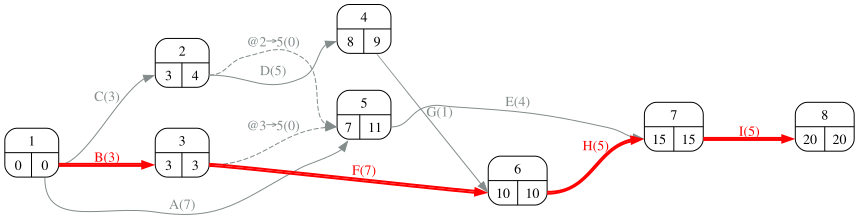

In [9]:
#| fig-cap: "Grafo PERT con tiempos y camino crítico"
#| label: fig-pert
proyecto.pert(durations=datos_proyecto['duration'], ranksep=1)

Cálculo de los tiempos tempranos y tardíos de los sucesos paso a paso (avance con los botones):

In [ ]:
proyecto.display_pert_pasos(datos_proyecto['duration'])

In [10]:
#| tbl-cap: "Duración media y varianza de cada ruta"
#| label: tbl-rutas
rutas = pd.DataFrame({'actividades': [' - '.join(R.columns[R.loc[r] == 1]) for r in R.index],
                      'media': medias, 'varianza': varianzas, 'σ': np.sqrt(varianzas)}, index=R.index).sort_values('media', ascending=False)
rutas.round(3)

,actividades,media,varianza,σ
Route_3,B - F - H - I,20,0.16,0.400
Route_4,C - D - G - H - I,19,8.81,2.968
Route_1,A - E - I,16,0.22,0.469
Route_2,B - E - I,12,0.17,0.412
Route_5,C - E - I,12,2.38,1.543


In [11]:
critica, segunda = rutas.index[0], rutas.index[1]
Markdown(f'La ruta crítica es {critica} ({rutas.loc[critica, "media"]:.0f} semanas, σ = {rutas.loc[critica, "σ"]:.2f}); '
         f'la segunda, {segunda} ({rutas.loc[segunda, "media"]:.0f} semanas, σ = {rutas.loc[segunda, "σ"]:.2f}), es mucho más variable.')

La ruta crítica es Route_3 (20 semanas, σ = 0.40); la segunda, Route_4 (19 semanas, σ = 2.97), es mucho más variable.

## Apartado 2

In [12]:
display(Markdown(pregunta_2))

2. Calcule la probabilidad de terminar en 22 semanas o menos según el método PERT (aproximación normal por la ruta crítica).  

In [13]:
plazo = 22
p_critica = norm.cdf((plazo - rutas.loc[critica, 'media']) / rutas.loc[critica, 'σ'])
Markdown(f'Por la ruta crítica: z = ({plazo} − {rutas.loc[critica, "media"]:.0f}) / {rutas.loc[critica, "σ"]:.2f} = {(plazo - rutas.loc[critica, "media"]) / rutas.loc[critica, "σ"]:.2f}, P = {p_critica:.3f}.')

Por la ruta crítica: z = (22 − 20) / 0.40 = 5.00, P = 1.000.

## Apartado 3

In [14]:
display(Markdown(pregunta_3))

3. Calcule la misma probabilidad considerando únicamente la segunda ruta. ¿Qué ruta da la probabilidad más baja? ¿Cuál es entonces una cota razonable de la probabilidad de cumplir el plazo?  

In [15]:
p_segunda = norm.cdf((plazo - rutas.loc[segunda, 'media']) / rutas.loc[segunda, 'σ'])
Markdown(f'''Por la segunda ruta: P = {p_segunda:.3f}. Para cumplir el plazo deben cumplirlo *todas* las rutas, así que la probabilidad real no puede superar la menor de las dos, {min(p_critica, p_segunda):.3f}; y como las rutas comparten actividades y no son independientes, tampoco es simplemente el producto. {"La ruta crítica sigue mandando también en probabilidad." if p_critica < p_segunda else "Es la segunda ruta, y no la crítica, la que manda en probabilidad, aunque no sea la más larga en media."}''')

Por la segunda ruta: P = 0.844. Para cumplir el plazo deben cumplirlo *todas* las rutas, así que la probabilidad real no puede superar la menor de las dos, 0.844; y como las rutas comparten actividades y no son independientes, tampoco es simplemente el producto. Es la segunda ruta, y no la crítica, la que manda en probabilidad, aunque no sea la más larga en media.

## Apartado 4

In [16]:
display(Markdown(pregunta_4))

4. Compruebe con Monte Carlo (10 000 réplicas, duraciones normales) cuál es la probabilidad real y explique por qué el método PERT se equivoca aquí más de lo habitual.  

In [17]:
rng = np.random.default_rng(7)
N = 10000
muestras = pd.DataFrame({a: np.clip(rng.normal(datos_proyecto.loc[a, 'duration'], datos_proyecto.loc[a, 'standard_deviation'], N), 0, None) for a in R.columns})
duracion_mc = (muestras @ R.T).max(axis='columns')
p_mc = float((duracion_mc <= plazo).mean())
pd.Series({'PERT (ruta crítica)': p_critica, 'segunda ruta': p_segunda, 'Monte Carlo': p_mc}).round(3).to_frame(f'P(T ≤ {plazo})')

,P(T ≤ 22)
PERT (ruta crítica),1.000
segunda ruta,0.844
Monte Carlo,0.841


El método PERT sólo mira la ruta de mayor duración media. Cuando otra ruta casi tan larga es mucho más variable, es *ella* la que más veces hace fallar el plazo: en muchas réplicas resulta la más larga. La probabilidad real es menor que la de cada ruta por separado, porque basta que una de ellas se pase. La regla práctica es examinar todas las rutas casi críticas y quedarse con la probabilidad más baja, o directamente simular.